# STIMTEC – Verification of the OGS T model (heat conduction in a granite disk) – ramped boundary temperature

This notebook verifies the OpenGeoSys `HEAT_CONDUCTION` model `T_granite_ramp.prj` against the analytical solution
for transient heat conduction in a disk with a time-dependent (ramped) boundary temperature.

| | |
|---|---|
| Domain | disk, $R = 0.1$ m, embedded inner circle $a = 0.066$ m, centre node $(0,0,0)$ |
| Initial condition | $T(r,0) = T_0 = 293$ K |
| Boundary condition | $T(R,t) = f(t)$ (Dirichlet): linear ramp 293 K → 363 K for $0 \le t \le 325$ s, then 363 K |
| Granite | $\rho = 2700$ kg/m³, $\lambda = 2.8$ W/(m K), $c_p = 790$ J/(kg K) |
| Time | $0 \le t \le 4000$ s, $\Delta t = 5$ s, backward Euler |

**Steps:** (1) run OGS, (2) analytical solution, (3) centre time series, (4) radial profiles,
(5) error norms over time, (6) mean temperature in the inner disk $r \le a$ (later needed for the volumetric strain),
(7) time-step convergence study.

Requirements: `ogs` (e.g. `pip install ogs`), `numpy`, `scipy`, `matplotlib`, `vtk`.
The notebook expects `T_granite_ramp.prj` and the mesh files (`domain.vtu`, `outer_boundary.vtu`, `inner_circle.vtu`,
`inner_disk.vtu`, `center.vtu`) in the same folder.

In [1]:
import shutil, subprocess, time
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import vtk
from vtk.util.numpy_support import vtk_to_numpy
from scipy.special import j0, j1, jn_zeros

HERE = Path.cwd()
PRJ = HERE / "T_granite_ramp.prj"
OUT = HERE / "results_ramp"
assert PRJ.exists(), f"{PRJ} not found - start the notebook in the folder containing the prj"

## 1 Parameters (read from the project file)

Material and boundary values are taken directly from `T_granite.prj`, so the analytical solution
always uses the same values as the simulation.

lambda = 2.8 W/(m K), cp = 790.0 J/(kg K), rho = 2700.0 kg/m3
T0 = 293.0 K, ramp to 363.0 K in 325 s (0.2154 K/s), plateau until 4000 s
kappa = 1.3127e-06 m2/s,  R^2/kappa = 7618 s = 2.12 h


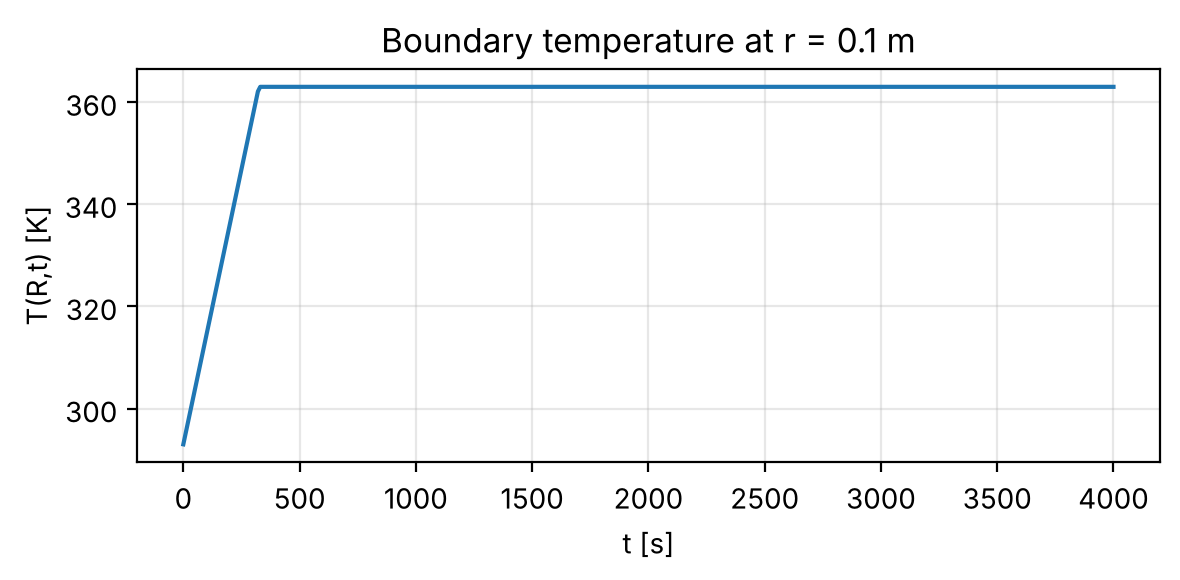

In [2]:
root = ET.parse(PRJ).getroot()
prop = {p.findtext("name"): float(p.findtext("value"))
        for p in root.iter("property")}
par = {p.findtext("name"): float(p.findtext("value"))
       for p in root.find("parameters") if p.findtext("type") == "Constant"}
curve = root.find("curves/curve")
bc_t = np.array(curve.findtext("coords").split(), float)
bc_T = np.array(curve.findtext("values").split(), float)

lam, cp, rho = prop["thermal_conductivity"], prop["specific_heat_capacity"], prop["density"]
T0 = par["T0"]
t_ramp, T_max = bc_t[1], bc_T[1]          # end of ramp, plateau temperature
v_ramp = (T_max - T0) / t_ramp            # heating rate of the boundary [K/s]
t_end = float(root.findtext(".//time_stepping/t_end"))
R, a_in = 0.1, 0.066
kappa = lam / (rho * cp)          # thermal diffusivity [m2/s]
t_char = R**2 / kappa             # characteristic diffusion time [s]
assert np.isclose(bc_T[0], T0) and np.allclose(bc_T[1:], T_max), "analytical solution assumes ramp + plateau"

print(f"lambda = {lam} W/(m K), cp = {cp} J/(kg K), rho = {rho} kg/m3")
print(f"T0 = {T0} K, ramp to {T_max} K in {t_ramp:.0f} s ({v_ramp:.4f} K/s), plateau until {t_end:.0f} s")
print(f"kappa = {kappa:.4e} m2/s,  R^2/kappa = {t_char:.0f} s = {t_char/3600:.2f} h")

tt = np.linspace(0, t_end, 400)
plt.figure(figsize=(6, 3))
plt.plot(tt, np.interp(tt, bc_t, bc_T))
plt.xlabel("t [s]"); plt.ylabel("T(R,t) [K]"); plt.title("Boundary temperature at r = 0.1 m")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 2 Run OGS

In [3]:
def run_ogs(prj, outdir):
    outdir = Path(outdir)
    if outdir.exists():
        shutil.rmtree(outdir)
    outdir.mkdir(parents=True)
    t = time.time()
    res = subprocess.run(["ogs", str(prj), "-o", str(outdir)],
                         cwd=HERE, capture_output=True, text=True)
    (outdir / "ogs_log.txt").write_text(res.stdout + res.stderr)
    if res.returncode != 0:
        print(res.stdout[-3000:], res.stderr[-3000:])
        raise RuntimeError("OGS run failed")
    print(f"OGS finished in {time.time() - t:.1f} s -> {outdir}")

run_ogs(PRJ, OUT)

OGS finished in 9.2 s -> /tmp/claude-0/nb2/results_ramp


### Helper functions for reading the results

In [4]:
def read_vtu(f):
    r = vtk.vtkXMLUnstructuredGridReader()
    r.SetFileName(str(f)); r.Update()
    g = r.GetOutput()
    pts = vtk_to_numpy(g.GetPoints().GetData())
    T = vtk_to_numpy(g.GetPointData().GetArray("temperature"))
    return pts, T, g

def read_pvd(outdir, meshname):
    # returns list of (time, vtu path)
    pvd = Path(outdir) / f"T_granite_{meshname}.pvd"
    return [(float(d.get("timestep")), Path(outdir) / d.get("file"))
            for d in ET.parse(pvd).getroot().iter("DataSet")]

def element_areas(g):
    # area of each triangle (vtkCellSizeFilter)
    f = vtk.vtkCellSizeFilter(); f.SetInputData(g)
    f.ComputeAreaOn(); f.ComputeLengthOff(); f.ComputeVolumeOff(); f.ComputeVertexCountOff()
    f.Update()
    return vtk_to_numpy(f.GetOutput().GetCellData().GetArray("Area"))

def mean_T_fe(g, T):
    # area-weighted mean of the linear FE field (exact for P1 triangles)
    A = element_areas(g)
    conn = vtk_to_numpy(g.GetCells().GetConnectivityArray()).reshape(-1, 3)
    return np.sum(A * T[conn].mean(axis=1)) / A.sum()

## 3 Analytical solution

Transient heat conduction in a disk (radial symmetry):

$$
\frac{\partial T}{\partial t} = \kappa \left( \frac{\partial^2 T}{\partial r^2} + \frac{1}{r}\frac{\partial T}{\partial r} \right),
\qquad \kappa = \frac{\lambda}{\rho c_p},
$$

with $T(r,0)=T_0$, $T(R,t)=f(t)$ and $T$ finite at $r=0$.

**Step response.** For a unit step of the boundary temperature, separation of variables gives
(Carslaw & Jaeger, 1959, §7.4)

$$
U(r,t) = 1 - \sum_{n=1}^{\infty} c_n\, J_0\!\left(\alpha_n \frac{r}{R}\right) e^{-\beta_n t},
\qquad c_n = \frac{2}{\alpha_n J_1(\alpha_n)},\quad \beta_n = \frac{\alpha_n^2 \kappa}{R^2},
$$

where $\alpha_n$ are the positive roots of $J_0(\alpha)=0$.

**Time-dependent boundary (Duhamel's theorem).** With $f(0)=T_0$,
$T(r,t) = T_0 + \int_0^t f'(\tau)\,U(r,t-\tau)\,d\tau$.
For the ramp $f'(\tau) = v = (T_{max}-T_0)/t_r$ for $\tau < t_r$ and $f'=0$ afterwards, with $m=\min(t,t_r)$:

$$
T(r,t) = T_0 + v\left[\, m - \sum_{n=1}^{\infty} c_n\, J_0\!\left(\alpha_n \frac{r}{R}\right)
\frac{e^{-\beta_n (t-m)} - e^{-\beta_n t}}{\beta_n} \right].
$$

For $t \ge t_r$ the bracket approaches $t_r$, i.e. $T \to T_{max}$.

The **mean temperature over the inner disk** $r \le a$ follows by integrating $J_0$
($\int_0^{x} s J_0(s)\,ds = x J_1(x)$), i.e. $J_0(\alpha_n r/R)$ is replaced by $2J_1(\alpha_n a/R)/(\alpha_n a/R)$:

$$
\bar T_a(t) = \frac{2}{a^2}\int_0^a T\,r\,dr
= T_0 + v\left[\, m - \sum_{n=1}^{\infty} c_n\, \frac{2 J_1(\alpha_n a/R)}{\alpha_n a/R}\,
\frac{e^{-\beta_n (t-m)} - e^{-\beta_n t}}{\beta_n} \right].
$$

Because the boundary temperature is continuous (no jump at $t=0$), the series converges quickly; 400 terms are used.

In [5]:
alpha = jn_zeros(0, 400)
coef = 2.0 / (alpha * j1(alpha))
beta = alpha**2 * kappa / R**2

def _time_factor(t):
    m = min(t, t_ramp)
    return m, (np.exp(-beta * (t - m)) - np.exp(-beta * t)) / beta

def T_analytical(r, t):
    r = np.atleast_1d(r).astype(float)
    m, g = _time_factor(t)
    return T0 + v_ramp * (m - j0(np.outer(r / R, alpha)) @ (coef * g))

def T_mean_analytical(a, t):
    x = alpha * a / R
    m, g = _time_factor(t)
    return T0 + v_ramp * (m - np.sum(coef * 2 * j1(x) / x * g))

def T_boundary(t):
    return np.interp(t, bc_t, bc_T)

# sanity checks
for t in (100.0, t_ramp, 2000.0):
    print(f"T(r=R, t={t:6.0f} s) = {T_analytical(R, t)[0]:8.3f} K   (BC: {T_boundary(t):.3f} K)")
print(f"T(r=0, t=0)        = {T_analytical(0.0, 0.0)[0]:8.3f} K   (should be T0)")
print(f"mean T(a=R, t=1e6) = {T_mean_analytical(R, 1e6):8.3f} K   (should be {T_max})")

T(r=R, t=   100 s) =  314.538 K   (BC: 314.538 K)
T(r=R, t=   325 s) =  363.000 K   (BC: 363.000 K)
T(r=R, t=  2000 s) =  363.000 K   (BC: 363.000 K)
T(r=0, t=0)        =  293.000 K   (should be T0)
mean T(a=R, t=1e6) =  363.000 K   (should be 363.0)


## 4 Temperature at the centre node $(0,0,0)$

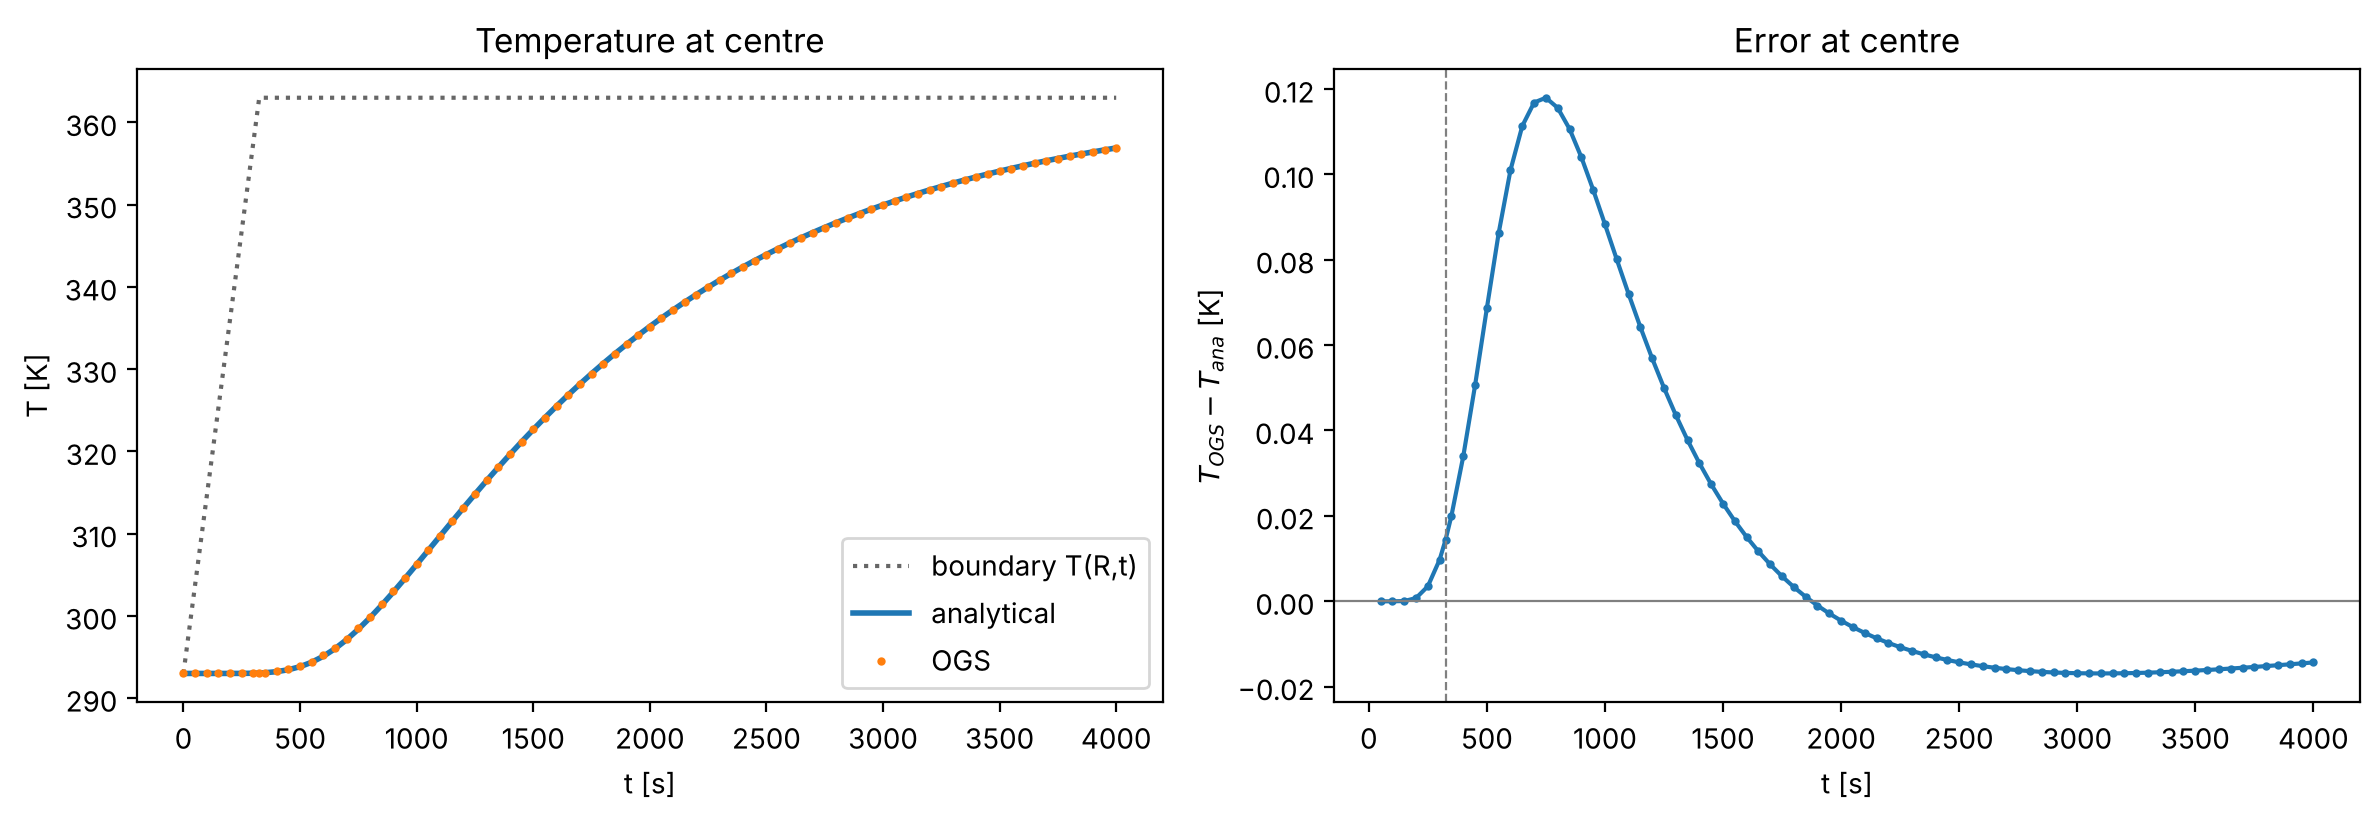

max |error| at centre (t > 0): 0.118 K


In [6]:
center = read_pvd(OUT, "center")
tc = np.array([t for t, _ in center])
Tc = np.array([read_vtu(f)[1][0] for _, f in center])
Tc_ana = np.array([T_analytical(0.0, t)[0] for t in tc])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(tc, T_boundary(tc), ":", color="0.4", label="boundary T(R,t)")
ax[0].plot(tc, Tc_ana, "-", lw=2, label="analytical")
ax[0].plot(tc, Tc, "o", ms=2, label="OGS")
ax[0].set(xlabel="t [s]", ylabel="T [K]", title="Temperature at centre")
ax[0].legend()
ax[1].plot(tc[1:], (Tc - Tc_ana)[1:], "-o", ms=2)
ax[1].axhline(0, color="0.5", lw=0.8); ax[1].axvline(t_ramp, ls="--", color="0.5", lw=0.8)
ax[1].set(xlabel="t [s]", ylabel=r"$T_{OGS} - T_{ana}$ [K]", title="Error at centre")
plt.tight_layout(); plt.show()

print(f"max |error| at centre (t > 0): {np.abs(Tc - Tc_ana)[1:].max():.3f} K")

## 5 Radial profiles

All nodes of the bulk mesh are plotted against their radius $r=\sqrt{x^2+y^2}$.
The scatter at a given $r$ shows how well the mesh preserves radial symmetry.

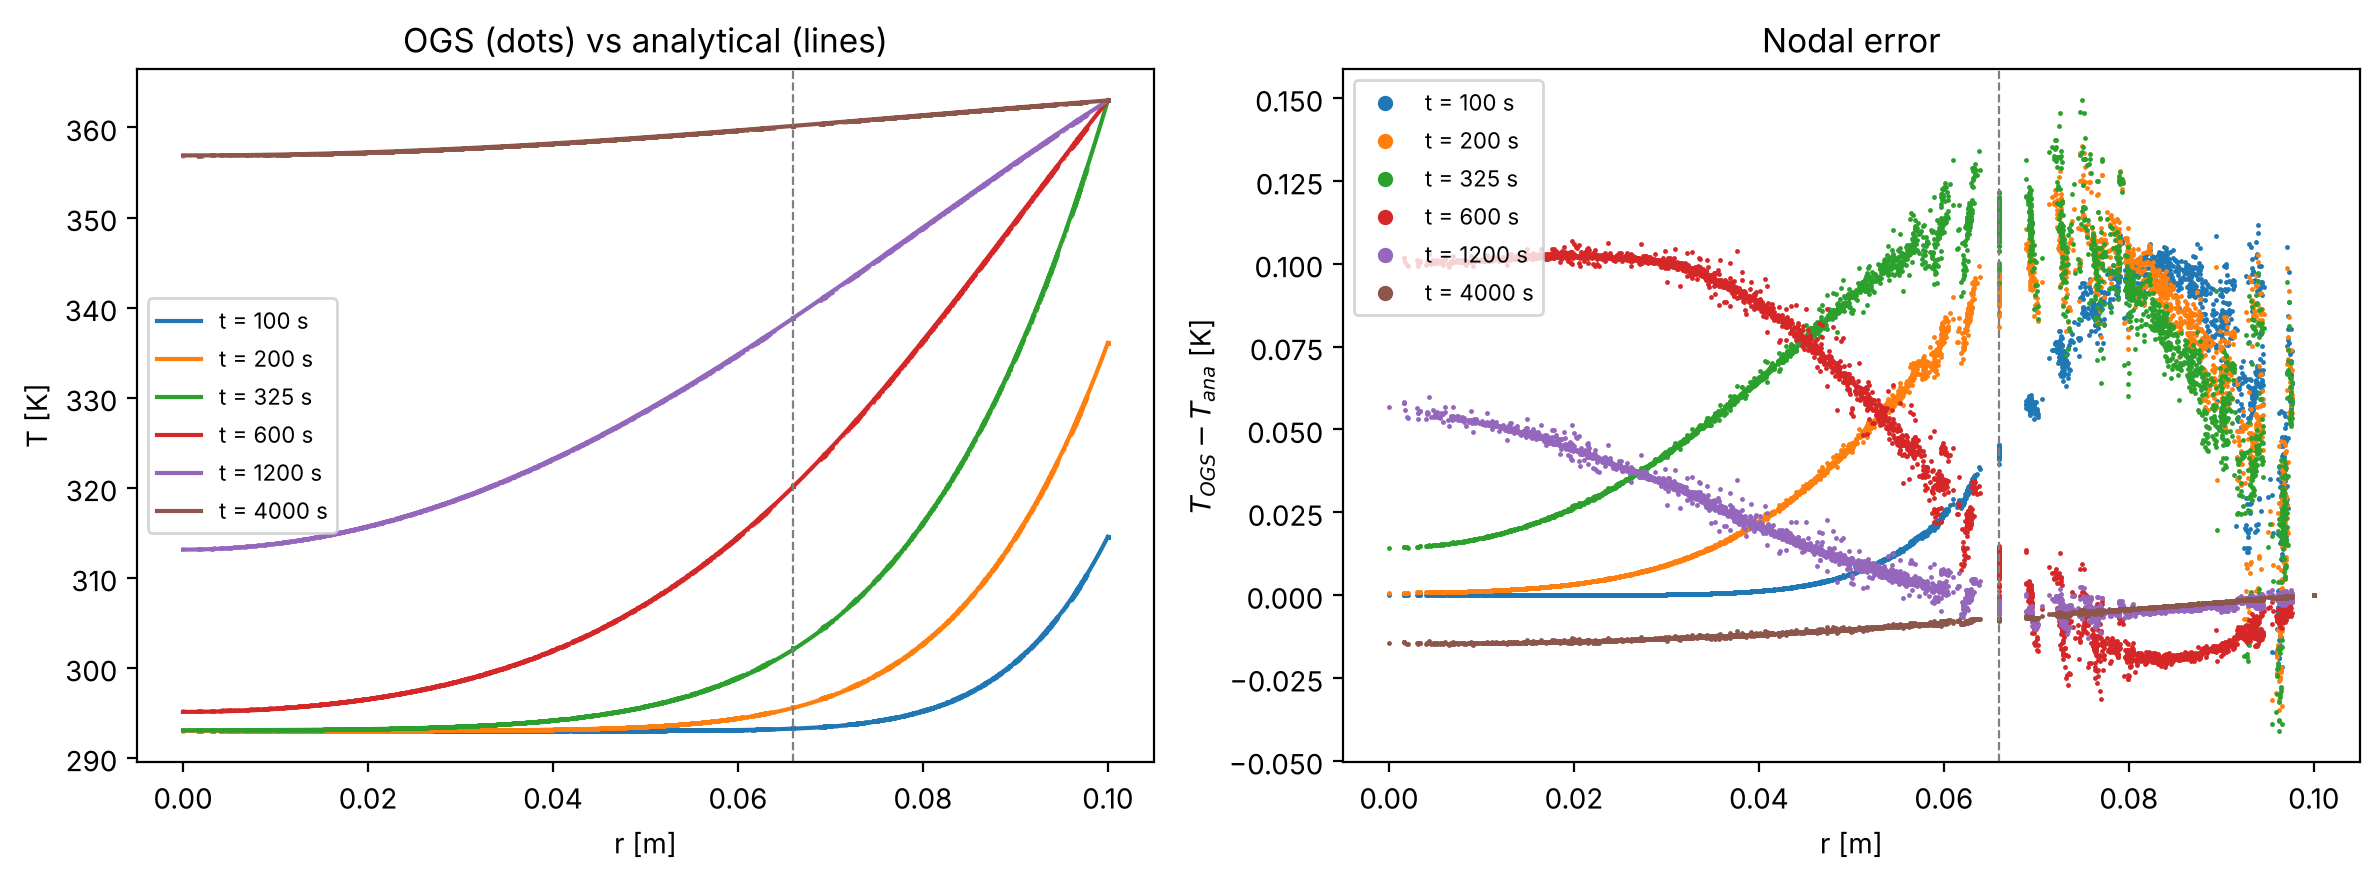

In [7]:
domain = dict(read_pvd(OUT, "domain"))
t_plot = [100, 200, 325, 600, 1200, 4000]
rr = np.linspace(0, R, 300)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for t in t_plot:
    pts, T, _ = read_vtu(domain[float(t)])
    r = np.hypot(pts[:, 0], pts[:, 1])
    l, = ax[0].plot(rr, T_analytical(rr, t), "-", label=f"t = {t:.0f} s")
    ax[0].plot(r, T, ".", ms=1.5, color=l.get_color(), alpha=0.5)
    ax[1].plot(r, T - T_analytical(r, t), ".", ms=1.5, color=l.get_color(), label=f"t = {t:.0f} s")
for a_ in ax:
    a_.axvline(a_in, ls="--", color="0.5", lw=0.8)
ax[0].set(xlabel="r [m]", ylabel="T [K]", title="OGS (dots) vs analytical (lines)")
ax[1].set(xlabel="r [m]", ylabel=r"$T_{OGS} - T_{ana}$ [K]", title="Nodal error")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8, markerscale=6)
plt.tight_layout(); plt.show()

## 6 Error norms over time

For each output time:

* maximum nodal error $\;e_\infty = \max_i |T_i - T_{ana}(r_i,t)|$
* discrete relative $L_2$ error of the temperature change
  $\;e_{L_2} = \lVert T - T_{ana}\rVert_2 \,/\, \lVert T_{ana} - T_0 \rVert_2$

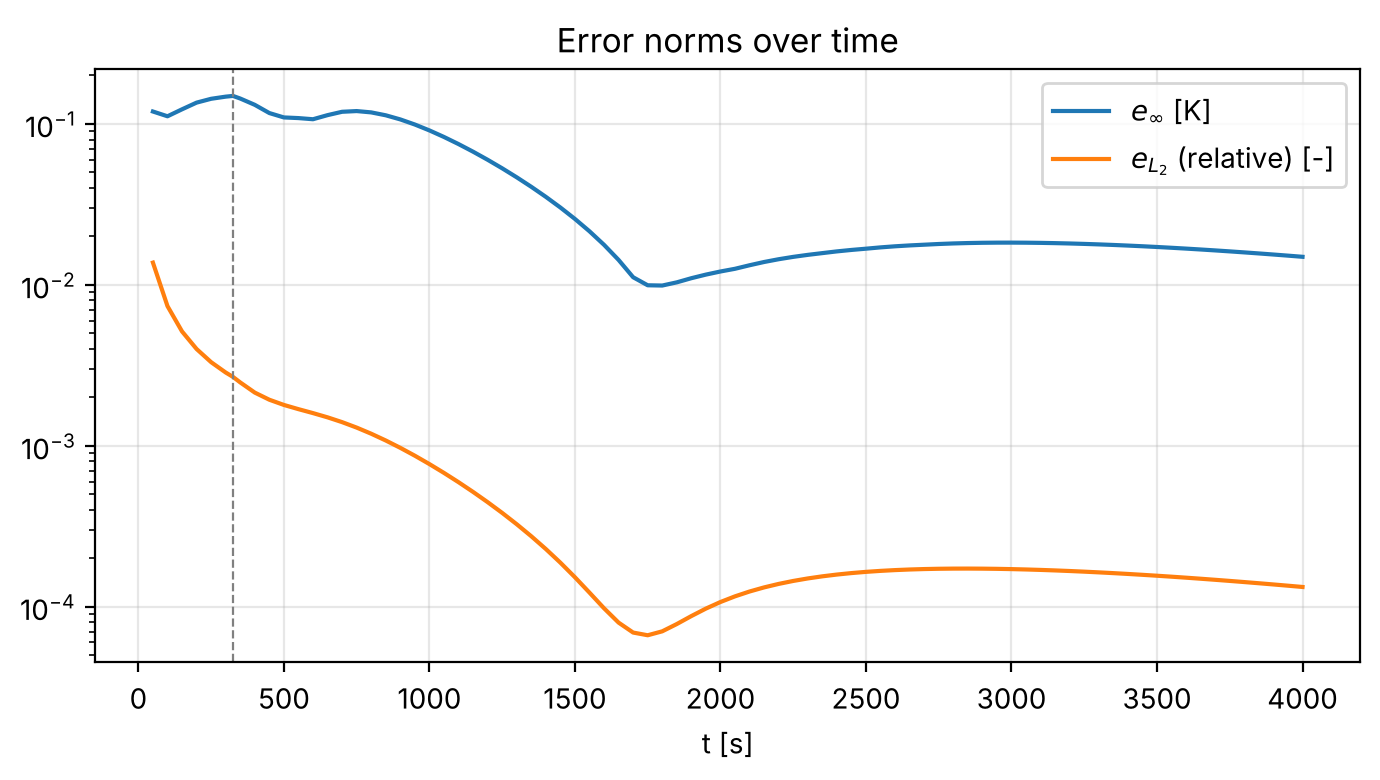

 t [s]     e_inf [K]   e_L2,rel [-]
   100      0.1116     7.38e-03
   200      0.1356     4.00e-03
   325      0.1493     2.68e-03
   600      0.1069     1.60e-03
  1200      0.0599     4.47e-04
  2000      0.0121     1.07e-04
  4000      0.0149     1.33e-04


In [8]:
rows = []
for t, f in read_pvd(OUT, "domain"):
    if t == 0:
        continue
    pts, T, _ = read_vtu(f)
    Ta = T_analytical(np.hypot(pts[:, 0], pts[:, 1]), t)
    rows.append((t, np.abs(T - Ta).max(),
                 np.linalg.norm(T - Ta) / np.linalg.norm(Ta - T0)))
err = np.array(rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(err[:, 0], err[:, 1], label=r"$e_\infty$ [K]")
ax.semilogy(err[:, 0], err[:, 2], label=r"$e_{L_2}$ (relative) [-]")
ax.axvline(t_ramp, ls="--", color="0.5", lw=0.8)
ax.set(xlabel="t [s]", title="Error norms over time"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(" t [s]     e_inf [K]   e_L2,rel [-]")
for t, ei, el in err:
    if t in (100, 200, 325, 600, 1200, 2000, 4000):
        print(f"{t:6.0f}   {ei:9.4f}   {el:10.2e}")

## 7 Mean temperature of the inner disk $r \le 0.066$ m

This quantity is the basis for the volumetric (thermal) strain later on,
e.g. $\varepsilon_V \approx \beta_T\,(\bar T_a - T_0)$ with the volumetric thermal expansion coefficient $\beta_T$.
The OGS value is the exact area integral of the linear FE field over the `inner_disk` sub-mesh.

inner disk area: FE 1.367645e-02 m2 vs pi a^2 1.368478e-02 m2 (-0.061 %)


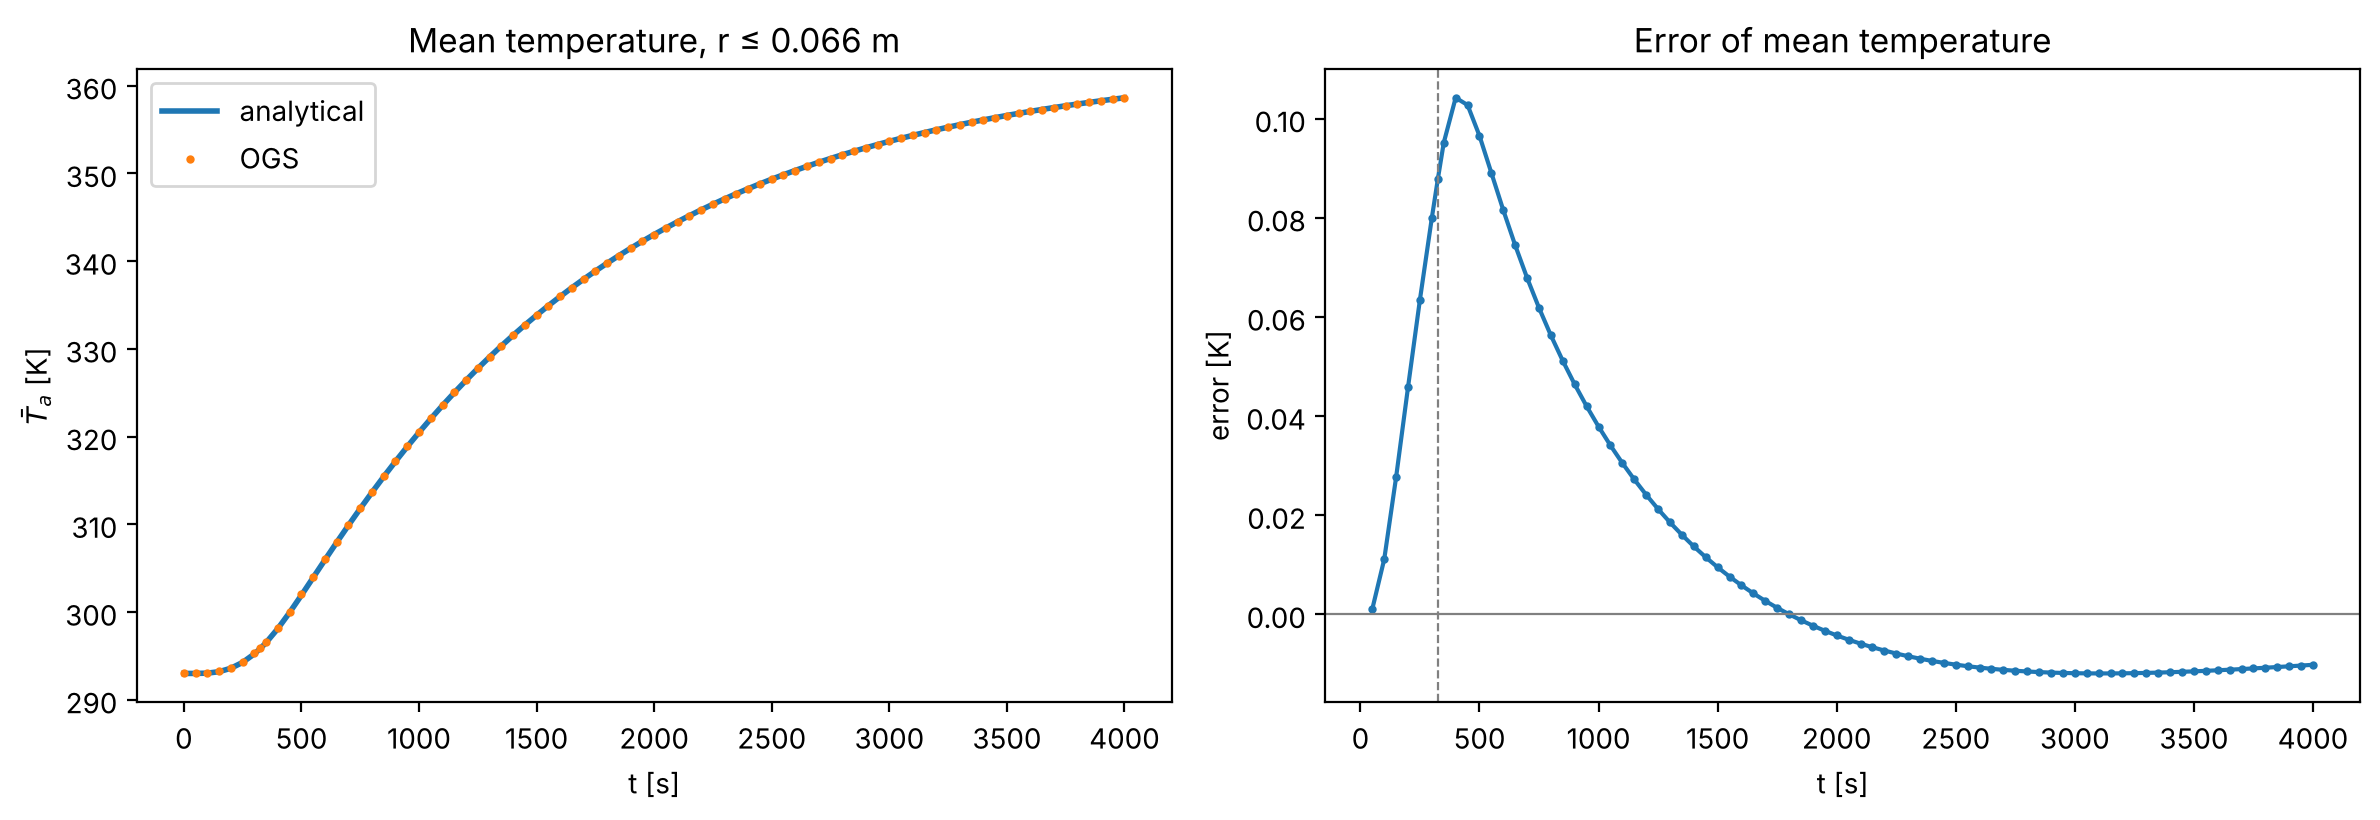

max |error| of mean T (t > 0): 0.1042 K


In [9]:
disk = read_pvd(OUT, "inner_disk")
td = np.array([t for t, _ in disk])
Tm = np.array([mean_T_fe(read_vtu(f)[2], read_vtu(f)[1]) for _, f in disk])
Tm_ana = np.array([T_mean_analytical(a_in, t) for t in td])

_, _, g0 = read_vtu(disk[0][1])
A_fe = element_areas(g0).sum()
print(f"inner disk area: FE {A_fe:.6e} m2 vs pi a^2 {np.pi*a_in**2:.6e} m2 "
      f"({100*(A_fe/(np.pi*a_in**2)-1):+.3f} %)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(td, Tm_ana, "-", lw=2, label="analytical")
ax[0].plot(td, Tm, "o", ms=2, label="OGS")
ax[0].set(xlabel="t [s]", ylabel=r"$\bar T_a$ [K]", title="Mean temperature, r ≤ 0.066 m"); ax[0].legend()
ax[1].plot(td[1:], (Tm - Tm_ana)[1:], "-o", ms=2)
ax[1].axhline(0, color="0.5", lw=0.8); ax[1].axvline(t_ramp, ls="--", color="0.5", lw=0.8)
ax[1].set(xlabel="t [s]", ylabel="error [K]", title="Error of mean temperature")
plt.tight_layout(); plt.show()
print(f"max |error| of mean T (t > 0): {np.abs(Tm - Tm_ana)[1:].max():.4f} K")

## 8 Time-step convergence study

Backward Euler is first-order in time, so the error at a fixed time should drop roughly linearly with $\Delta t$
until the spatial discretisation error dominates. The project file is copied with modified time stepping
($t_{end} = 650$ s, i.e. ramp plus the same time again, output only at the end) and run for several $\Delta t$
(all dividing $t_r = 325$ s, so the kink of the boundary curve falls on a time step).
Set `RUN_STUDY = False` to skip (≈ 10–30 s runtime).

OGS finished in 0.3 s -> /tmp/claude-0/nb2/results_dtstudy_ramp/dt_65


OGS finished in 0.4 s -> /tmp/claude-0/nb2/results_dtstudy_ramp/dt_32.5


OGS finished in 0.6 s -> /tmp/claude-0/nb2/results_dtstudy_ramp/dt_16.25


OGS finished in 0.9 s -> /tmp/claude-0/nb2/results_dtstudy_ramp/dt_8.125


OGS finished in 1.5 s -> /tmp/claude-0/nb2/results_dtstudy_ramp/dt_4.0625


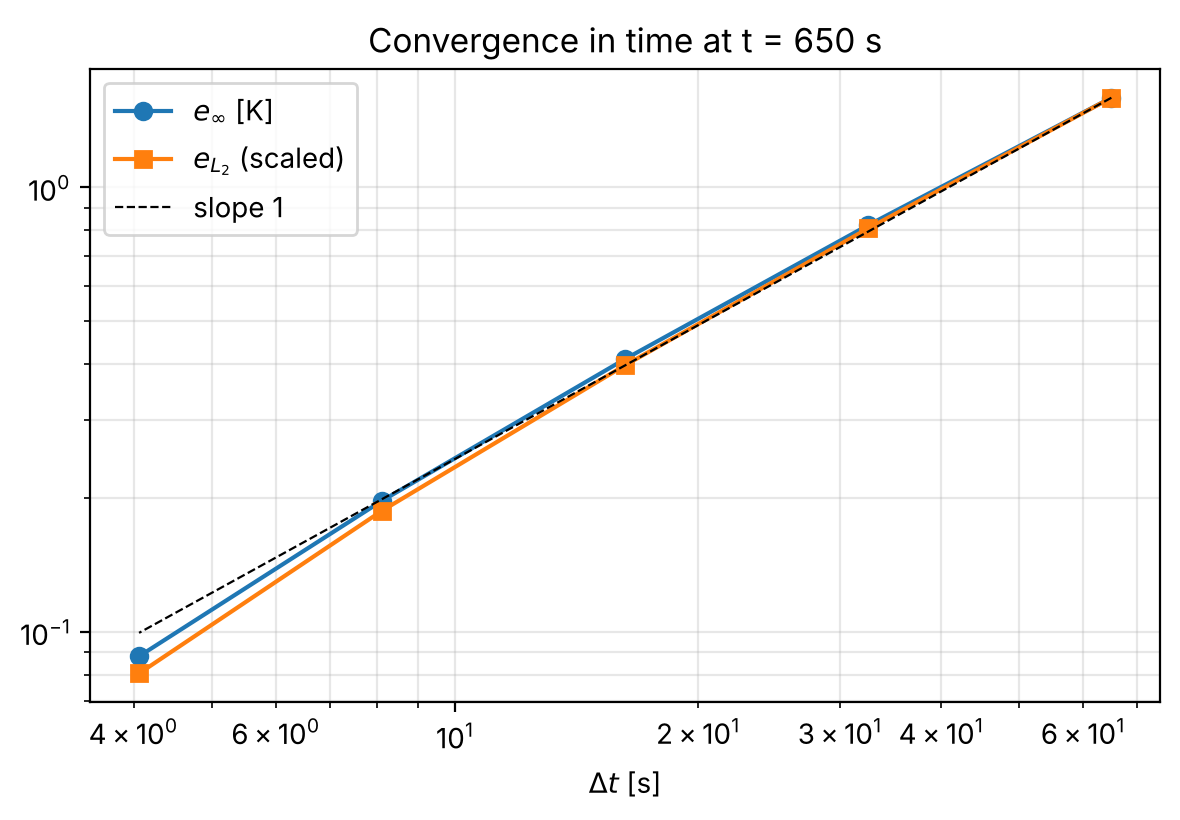

 dt [s]   e_inf [K]   e_L2,rel   order(e_inf)
    65      1.5910    2.27e-02   
  32.5      0.8224    1.15e-02   0.95
 16.25      0.4110    5.68e-03   1.00
 8.125      0.1972    2.67e-03   1.06
4.0625      0.0881    1.15e-03   1.16


In [10]:
RUN_STUDY = True
t_check = 650.0
dts = [65, 32.5, 16.25, 8.125, 4.0625]

def make_variant(dt, t_end, name):
    tree = ET.parse(PRJ); r = tree.getroot()
    ts = r.find(".//time_stepping")
    ts.find("t_end").text = str(t_end)
    pair = ts.find("timesteps/pair")
    pair.find("repeat").text = str(int(round(t_end / dt)))
    pair.find("delta_t").text = str(dt)
    out = r.find(".//output")
    out.find("timesteps/pair/each_steps").text = str(int(round(t_end / dt)))
    fot = out.find("fixed_output_times")
    if fot is not None:
        out.remove(fot)
    meshes = out.find("meshes")
    for m in list(meshes):
        if m.text.strip() != "domain":
            meshes.remove(m)
    out.find("prefix").text = "T_granite_{:meshname}"
    p = HERE / f"{name}.prj"
    tree.write(p, encoding="ISO-8859-1", xml_declaration=True)
    return p

if RUN_STUDY:
    conv = []
    for dt in dts:
        p = make_variant(dt, t_check, f"_dtstudy_ramp_{dt:g}")
        od = HERE / "results_dtstudy_ramp" / f"dt_{dt:g}"
        run_ogs(p, od); p.unlink()
        t_last, f_last = read_pvd(od, "domain")[-1]
        pts, T, _ = read_vtu(f_last)
        Ta = T_analytical(np.hypot(pts[:, 0], pts[:, 1]), t_last)
        conv.append((dt, np.abs(T - Ta).max(), np.linalg.norm(T - Ta) / np.linalg.norm(Ta - T0)))
    conv = np.array(conv)

    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.loglog(conv[:, 0], conv[:, 1], "o-", label=r"$e_\infty$ [K]")
    ax.loglog(conv[:, 0], conv[:, 2] * conv[0, 1] / conv[0, 2], "s-", label=r"$e_{L_2}$ (scaled)")
    ref = conv[0, 1] * (conv[:, 0] / conv[0, 0])
    ax.loglog(conv[:, 0], ref, "k--", lw=0.8, label="slope 1")
    ax.set(xlabel=r"$\Delta t$ [s]", title=f"Convergence in time at t = {t_check:.0f} s"); ax.legend()
    ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

    print(" dt [s]   e_inf [K]   e_L2,rel   order(e_inf)")
    for i, (dt, ei, el) in enumerate(conv):
        o = "" if i == 0 else f"{np.log(conv[i-1,1]/ei)/np.log(conv[i-1,0]/dt):.2f}"
        print(f"{dt:6g}   {ei:9.4f}   {el:9.2e}   {o}")

## 9 Summary

In [11]:
print("Verification summary - OGS HEAT_CONDUCTION vs analytical (Bessel series)")
print(f"  centre node     : max |error| = {np.abs(Tc - Tc_ana)[1:].max():.3f} K")
print(f"  all nodes       : max |error| = {err[:,1].max():.3f} K (at t = {err[err[:,1].argmax(),0]:.0f} s)")
print(f"  inner-disk mean : max |error| = {np.abs(Tm - Tm_ana)[1:].max():.4f} K")
print(f"  end state       : T_centre = {Tc[-1]:.4f} K (analytical {Tc_ana[-1]:.4f} K, plateau {T_max} K)")
if RUN_STUDY:
    order = np.log(conv[0,1]/conv[-1,1]) / np.log(conv[0,0]/conv[-1,0])
    print(f"  time convergence: mean observed order {order:.2f} (backward Euler: 1)")

Verification summary - OGS HEAT_CONDUCTION vs analytical (Bessel series)
  centre node     : max |error| = 0.118 K
  all nodes       : max |error| = 0.149 K (at t = 325 s)
  inner-disk mean : max |error| = 0.1042 K
  end state       : T_centre = 356.8814 K (analytical 356.8958 K, plateau 363.0 K)
  time convergence: mean observed order 1.04 (backward Euler: 1)


**Interpretation.** Because the boundary temperature rises continuously (no jump at $t=0$), the
temperature gradients stay moderate and the errors are small throughout. The largest deviations occur
during and shortly after the ramp, when the heating front moves into the disk; they are dominated by
the first-order time discretisation (observed order ≈ 1). After the ramp the field relaxes towards
the plateau temperature of 363 K and the errors decay. Further reduction is possible with smaller
$\Delta t$ and/or a finer mesh (`make_circle_mesh.py --lc ...`).